# Signal Audit 3: Three Errors in the Signals Table

This notebook shows, with data, the three main errors of the signals table:

| # | Column | Error |
|---|---|---|
| 1 | `tp_*` (time of play) | Impossible session lengths; night, weekend and entropy on the wrong scale; days that are not updated |
| 2 | `days_since_bet` | Uses data from **7 days after** its date |
| 3 | `active_days_*` | Counts days played **only with playable bonus** |

**Data:** brands 14, 23, 64, 72 and 73. Part 1 uses the cache of notebooks 01 and 02. Parts 2 and 3 compare the table with the daily activity on local files (no S3). Only aggregates are shown.

In [2]:
# reload the modules when they change, with no kernel restart
%reload_ext autoreload
%autoreload 2

import datetime as dt
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

sys.path.insert(0, str(Path.cwd()))
import audit
import plots
import stats
import evidence as ev

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
REFRESH = False
cfg = audit.load_config()
rc_cfg = audit.load_config(Path("metrics_recomputed.yaml"))

## 1. Time of Play (`tp_*`)

These columns start on **6 July 2026**. I compare them with the same signals recomputed from every bet (`02_validation`, part B).

### 1.1 Session length

A session cannot last more than a day. The table has sessions of **up to 28 days** and many of **exactly 1 second** (one bet). Recomputed, the centre is the same and these tails disappear.

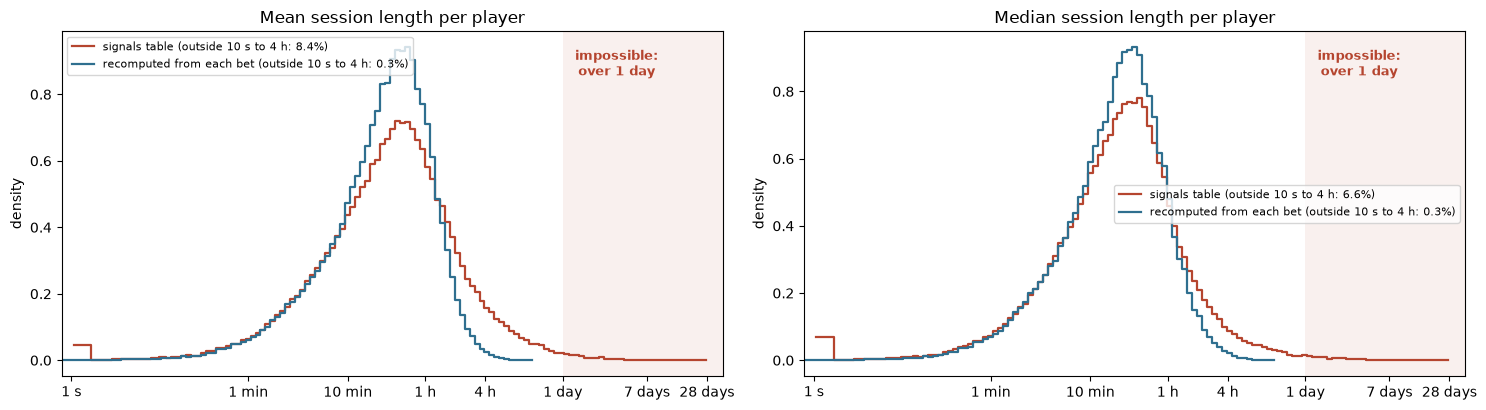

,rows,median (min),max (days),outside 10 s to 4 h %
table: mean,4715183.0,27.70,27.94,8.39
recomputed: mean,97964.0,25.13,0.48,0.30
table: median,4715183.0,20.02,27.94,6.58
recomputed: median,97964.0,19.55,0.49,0.28


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, (table, mine, title) in zip(axes, [
        ("session_duration_avg_secs", "rc_player_avg_session_secs", "Mean session length per player"),
        ("median_session_duration_secs", "rc_player_median_session_secs", "Median session length per player")]):
    plots.overlay([(cfg, table, "signals table", plots.TABLE_C), (rc_cfg, mine, "recomputed from each bet", plots.MINE_C)],
                    ax, log_x=True)
    ax.axvspan(86400, 3.5e6, color=plots.TABLE_C, alpha=0.08, lw=0)
    ax.text(3e5, 0.95, "impossible:\nover 1 day", transform=ax.get_xaxis_transform(), ha="center", va="top",
            color=plots.TABLE_C, fontsize=9, fontweight="bold")
    ticks = [(1, "1 s"), (60, "1 min"), (600, "10 min"), (3600, "1 h"), (14400, "4 h"), (86400, "1 day"), (7 * 86400, "7 days"), (28 * 86400, "28 days")]
    ax.set_xticks([t for t, _ in ticks], [l for _, l in ticks])
    ax.minorticks_off()
    ax.set(xlim=(0.8, 3.5e6), title=title, ylabel="density")
plt.tight_layout()
plt.show()

rows = {}
for label, conf, name in [("table: mean", cfg, "session_duration_avg_secs"), ("recomputed: mean", rc_cfg, "rc_player_avg_session_secs"),
                          ("table: median", cfg, "median_session_duration_secs"), ("recomputed: median", rc_cfg, "rc_player_median_session_secs")]:
    p, _ = audit.metric_data(conf, name)
    rows[label] = {"rows": int(p["n"]), "median (min)": p["quantiles"][4] / 60, "max (days)": p["max"] / 86400,
                   "outside 10 s to 4 h %": 100 * (p["below_range"] + p["above_range"]) / p["n"]}
display(pd.DataFrame(rows).T.round(2))

### 1.2 Night, weekend and entropy: the wrong scale

They should be shares from 0 to 1, but they go above 1, and the values sit on exact fractions (dotted lines):

- **weekend:** values at 3.5/k → the share **divided by 2/7**;
- **night:** values at 4/k → the share **divided by 6/24**;
- **entropy:** values at log2(k) → entropy **in bits, not divided by its maximum** (log2 24 = 4.58).

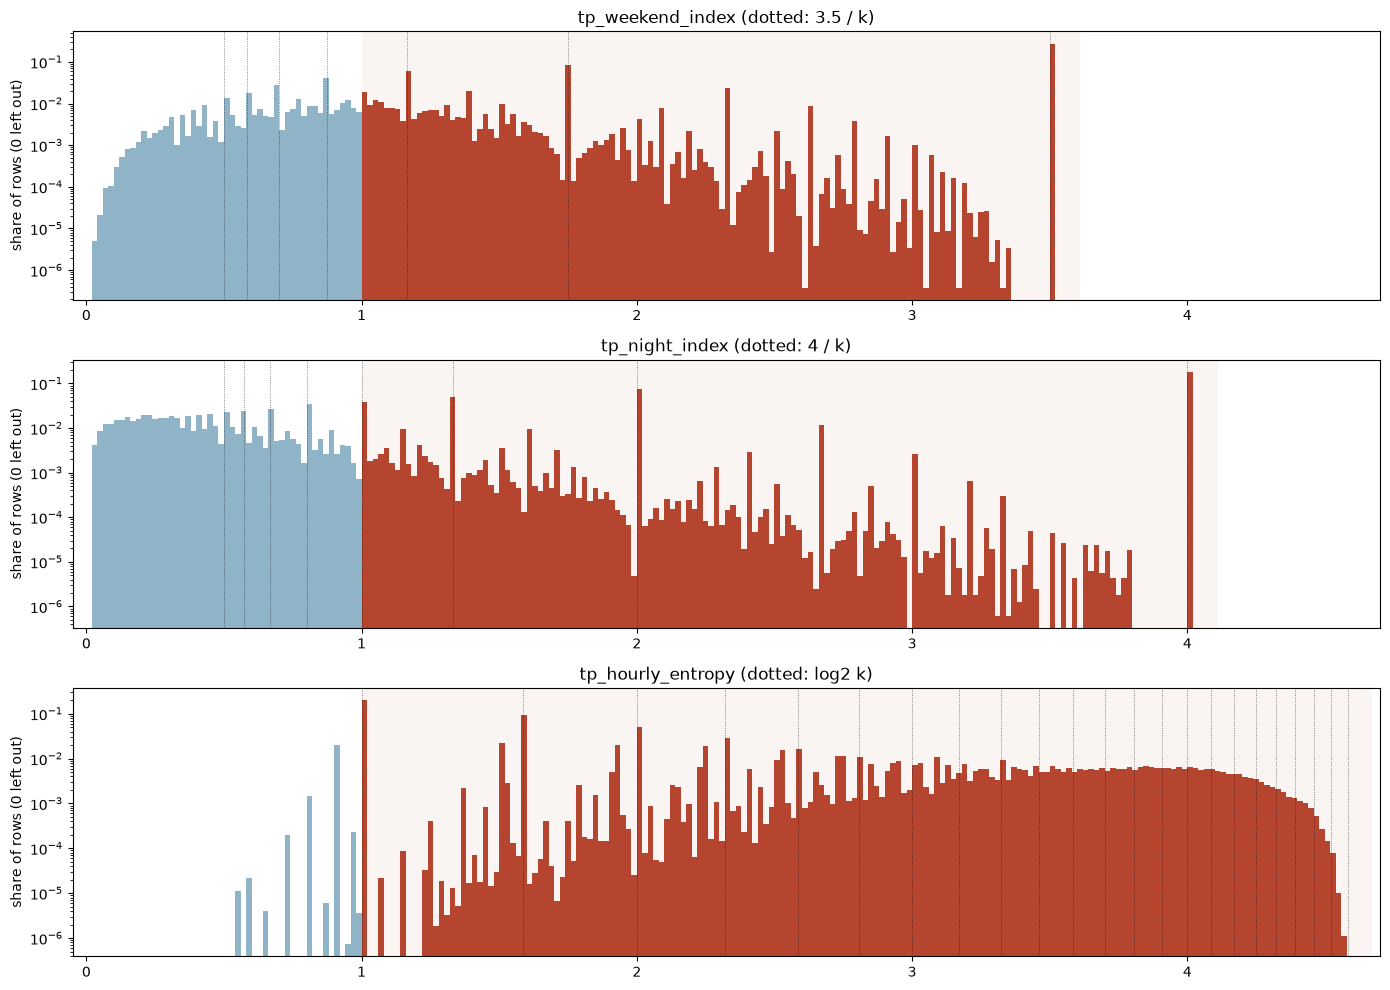

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
plots.scale(cfg, "weekend_index", "weekend", "tp_weekend_index (dotted: 3.5 / k)", axes[0])
plots.scale(cfg, "night_index", "night", "tp_night_index (dotted: 4 / k)", axes[1])
plots.scale(cfg, "hourly_entropy", "entropy", "tp_hourly_entropy (dotted: log2 k)", axes[2])
for ax in axes:
    ax.set_xlim(-0.05, 4.7)
plt.tight_layout()
plt.show()

**Test:** back on the 0 to 1 scale, weekend and entropy look like the recomputed shares (median 0.40 vs 0.41, and 0.53 vs 0.47). Night does not (0.20 vs 0.41), so its night hours are probably also different.

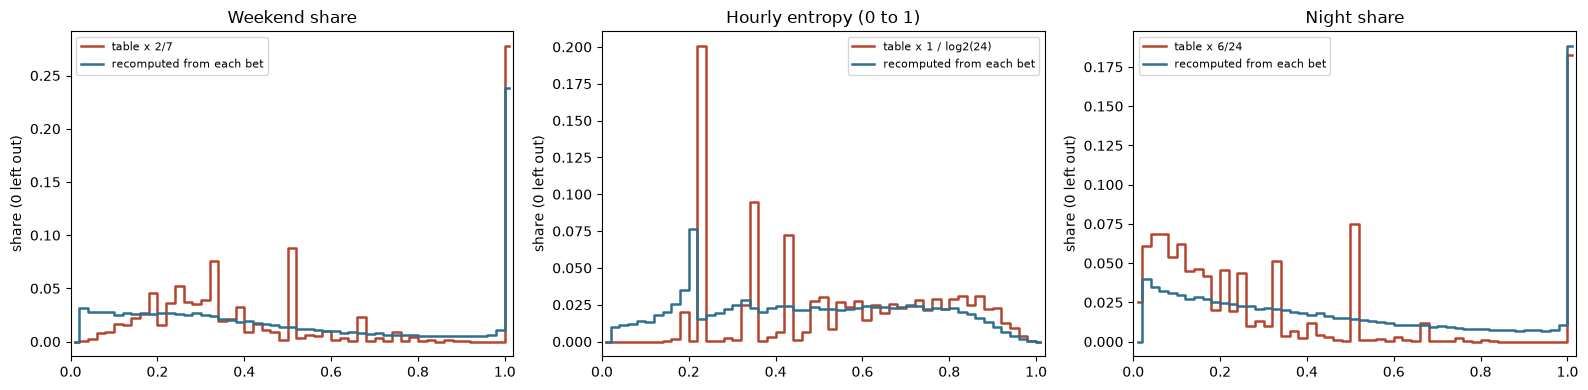

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
plots.rescaled(cfg, rc_cfg, "weekend_index", "rc_weekend_share", 2 / 7, "2/7", axes[0])
plots.rescaled(cfg, rc_cfg, "hourly_entropy", "rc_hourly_entropy", 1 / 4.585, "1 / log2(24)", axes[1])
plots.rescaled(cfg, rc_cfg, "night_index", "rc_night_share_tod", 1 / 4, "6/24", axes[2])
for ax, t in zip(axes, ("Weekend share", "Hourly entropy (0 to 1)", "Night share")):
    ax.set_title(t)
plt.tight_layout()
plt.show()

### 1.3 When and where

Impossible values per day and brand, 1 June to 15 October 2026.

- **Every brand**, from **6 July**: the error is in the calculation, not in one brand.
- **Three stages** (dashed lines): 6 July (start), 1 August (many more rows; worst sessions) and 19 August (sessions improve).
- **Frozen days** (red lines): the `tp_*` columns are exactly the same as the day before, while the rest of the table changes.

,metric,rows,impossible,impossible %,first day,last day,worst day,brand 14 %,brand 23 %,brand 64 %,brand 72 %,brand 73 %,no brand_id %
0,active_days_l30d,12678683,0,0.00,None,None,None,0.00,0.00,0.00,0.00,0.00,0.00
1,hold_pct_l30d,12412200,232,0.00,2026-06-17,2026-08-17,2026-07-16,0.00,0.00,0.00,0.01,0.00,0.00
2,hourly_entropy,25888187,7189973,27.77,2026-07-06,2026-10-15,2026-08-18,16.37,38.07,28.77,22.75,29.87,34.41
3,median_session_duration_secs,15535340,116508,0.75,2026-07-06,2026-10-15,2026-07-06,0.75,0.46,0.40,0.37,1.42,0.48
4,night_index,25888187,2094223,8.09,2026-07-06,2026-10-15,2026-07-12,8.50,6.64,9.08,9.63,7.28,7.63
5,session_duration_avg_secs,15535340,165342,1.06,2026-07-06,2026-10-15,2026-07-06,0.96,0.75,0.63,0.57,1.93,0.75
6,session_gap_avg_hours,9323394,80390,0.86,2026-07-06,2026-10-15,2026-07-06,1.03,0.31,0.56,1.00,1.30,0.45
7,weekend_index,25888187,6053177,23.38,2026-07-06,2026-10-15,2026-07-20,17.16,26.49,26.31,22.48,23.79,25.19


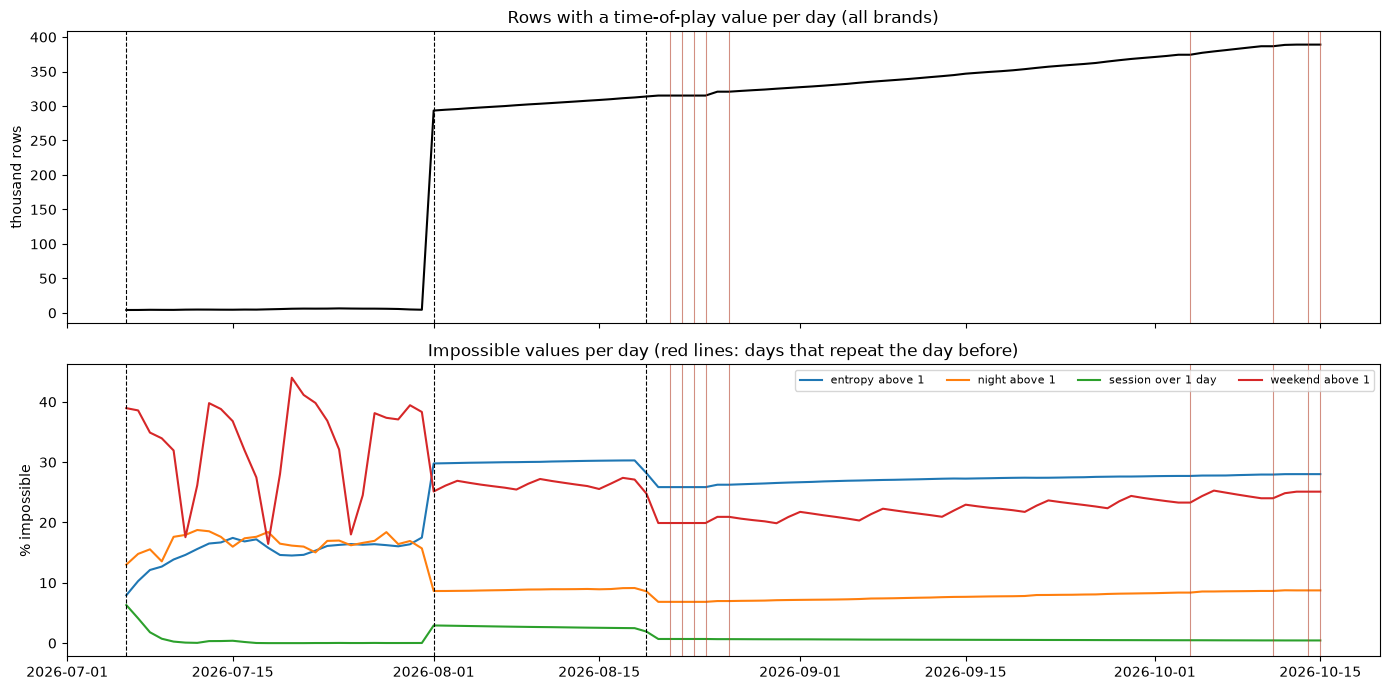

kind,day,rows,impossible,same as the day before,active_days_l30d changes
0,2026-08-21,315153.0,21562.0,True,True
1,2026-08-22,315153.0,21562.0,True,True
2,2026-08-23,315153.0,21562.0,True,True
3,2026-08-24,315153.0,21562.0,True,True
4,2026-08-26,320786.0,22376.0,True,True
5,2026-10-04,374358.0,31361.0,True,True
6,2026-10-11,386677.0,33444.0,True,True
7,2026-10-14,389047.0,34011.0,True,True
8,2026-10-15,389047.0,34011.0,True,True


In [6]:
by_day = audit.flags_by_day(cfg, "gld_player_signals_daily", start="2026-06-01", end="2026-10-15")
repeated = ev.repeated_days(by_day)
display(stats.impossible_summary(by_day).round(2))
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
plots.tp_daily(by_day[by_day["day"] >= dt.date(2026, 7, 1)], repeated, axes)
plt.tight_layout()
plt.show()
display(repeated)

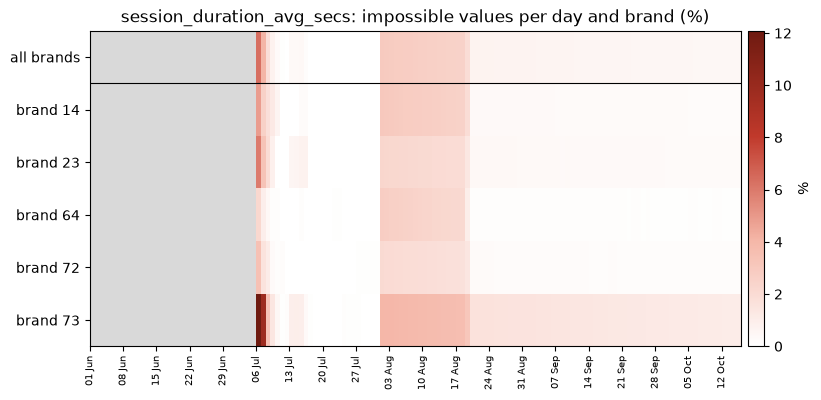

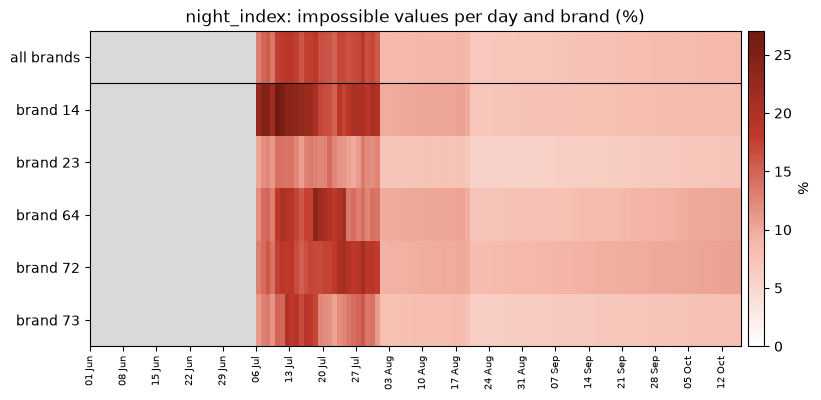

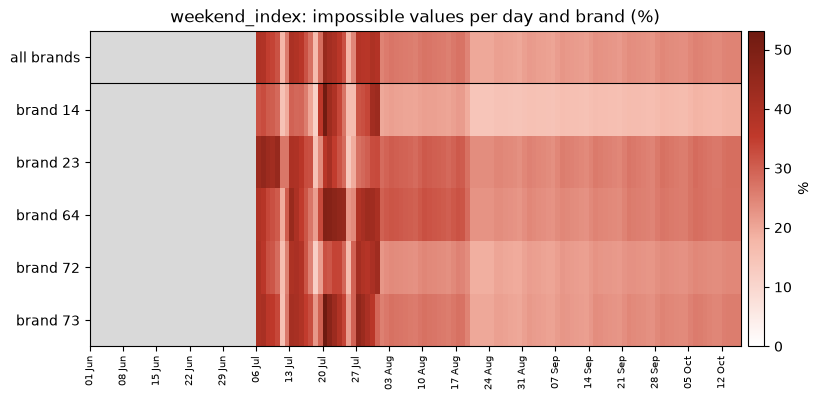

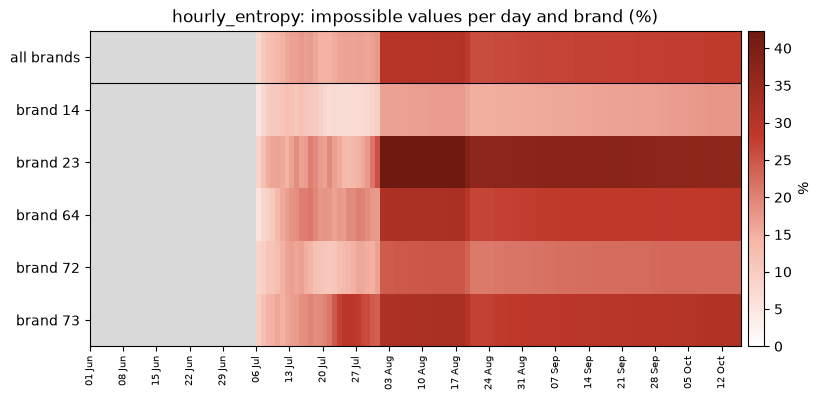

In [7]:
for name in ["session_duration_avg_secs", "night_index", "weekend_index", "hourly_entropy"]:
    plots.by_day(by_day, name)
    plt.show()

## 2. `days_since_bet` Uses Later Data

`days_since_bet` should be the days from the last bet **up to the date D**. I recompute it on D and on the days around D, and compare.

### 2.1 Empty before August 2026

Until May 2026 it is **0 for almost every player**. It is filled from 1 August 2026.

In [8]:
over_time = ev.recency_over_time()
fig, ax = plt.subplots(figsize=(13, 3.8))
plots.zero_share(over_time, ax)
plt.tight_layout()
plt.show()

### 2.2 Which day does it match?

It matches the recency of **D + 7** for about **92%** of the players, and any other day for about **5%**.

In [9]:
evidence, shifts = ev.recency_evidence(refresh=REFRESH)
fig, ax = plt.subplots(figsize=(13, 4.2))
plots.shift_match(shifts, ax)
plt.tight_layout()
plt.show()
display(evidence[["brand", "day", "players", "match as of the day %", "match 7 days later %"]].round(1))

,brand,day,players,match as of the day %,match 7 days later %
0,14,2026-08-01,10535,9.7,97.3
1,14,2026-08-02,10770,9.0,97.4
2,14,2026-08-25,12175,5.9,93.9
3,14,2026-09-01,10363,3.3,87.3
4,14,2026-09-06,9881,4.3,88.1
5,23,2026-08-01,23919,14.4,98.5
6,23,2026-08-02,23863,13.1,98.5
7,23,2026-08-25,24202,11.8,87.1
8,23,2026-09-01,24913,7.1,78.9
9,23,2026-09-06,25117,9.0,77.9


### 2.3 The proof

If the table says the last bet is **more recent than any bet up to D**, that bet must be after D. This happens for 9% to 23% of the players, and **96% to 99.7%** of them do bet in the next 7 days.

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
plots.leak_proof(evidence, axes[0])
diff = sum(ev.recency_differences(b, dt.date(2026, 9, 1)) for b in ev.BRANDS)
plots.recency_differences(diff, axes[1])
plt.tight_layout()
plt.show()

### 2.4 Why it matters

A column with future data predicts too well: AUC **0.99** to predict a bet in the next 7 days, against **0.79 to 0.87** for the real recency. A model trained with it would look great in testing and fail in production.

`churn_score` uses it, but its AUC (0.78 to 0.83) does not show the leak. It is still built on a wrong input.

In [11]:
fig, ax = plt.subplots(figsize=(13, 4.2))
plots.auc(evidence, ax)
plt.tight_layout()
plt.show()

## 3. `active_days_*` Counts Days Played Only With Playable Bonus

An active day is a day with a stake from **real money or released bonus**. Playable bonus is not the player's money yet, so a day played only with it is not active. I count active days in two ways: **official** and **any wallet**.

### 3.1 How common are these days?

**5% to 32%** of the player-days, depending on brand and month. Brand 72 has the most.

In [12]:
share = ev.playable_only_share()
fig, ax = plt.subplots(figsize=(13, 3.8))
plots.playable_share(share[share.index >= pd.Period("2025-07")], ax)
plt.tight_layout()
plt.show()

### 3.2 Which definition does the table use?

The table equals the **any wallet** count for 96% to 100% of the players, and the **official** count for only 48% to 86%. It never counts fewer days than the official one.

In [13]:
active_over_time = ev.active_days_over_time(refresh=REFRESH)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ev.WINDOWS):
    plots.active_match(active_over_time, col, ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()
display(active_over_time.groupby("column")[["= official %", "= any wallet %", "above official %", "below official %"]]
        .median().round(1))

,= official %,= any wallet %,above official %,below official %
column,,,,
active_days_l30d,56.8,98.4,43.2,0.0
active_days_l7d,86.4,99.7,13.6,0.0
active_days_l90d,48.1,96.2,51.9,0.0


In [14]:
diff = sum(ev.active_days_differences(b, dt.date(2026, 9, 1)) for b in ev.BRANDS).fillna(0)
fig, ax = plt.subplots(figsize=(13, 4))
plots.active_differences(diff, ax)
plt.tight_layout()
plt.show()

### 3.3 Why it matters

**17% to 34%** of the players who bet in the last 30 days used **only playable bonus**. Officially they have **0 active days**, but the table gives all of them at least one.

In [15]:
fa = ev.false_actives()
fig, ax = plt.subplots(figsize=(13, 4.2))
plots.false_actives(fa, ax)
plt.tight_layout()
plt.show()
display(fa.round(2))

,brand,players with a bet in 30 days,only playable bonus,only playable bonus %,"of those, table active days > 0 %",their mean table active days
0,14,10363,3571,34.46,100.0,1.09
1,23,24913,4827,19.38,100.0,1.75
2,64,14092,2865,20.33,100.0,1.38
3,72,18450,5635,30.54,100.0,1.22
4,73,26045,4396,16.88,100.0,1.61


## 4. Other Points of the Error List

Evidence for the points of the PDF that are not in sections 1 to 3. Local files only.

### 4.1 `tenure_days`

Tenure must grow by exactly the days between two snapshots. Before August 2026 this happens for only 11% to 33% of the players; from September, for 99%.

In [16]:
growth = ev.tenure_growth()
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
plots.tenure(growth, axes)
plt.tight_layout()
plt.show()
display(growth.pivot_table(index="day", columns="brand", values="share_growing_as_expected").mul(100).round(1))

brand,14,23,64,72,73
day,,,,,
2025-08-01,28.2,21.1,21.2,13.5,23.2
2025-09-01,28.3,23.4,20.9,14.1,23.5
2025-10-01,29.0,25.5,22.2,14.2,22.6
2025-11-01,32.7,23.7,21.3,15.7,24.1
2025-12-01,25.0,17.8,12.4,11.0,19.8
2026-01-01,31.2,19.4,11.3,13.5,19.5
2026-02-01,29.0,23.7,14.0,17.9,23.9
2026-03-01,20.0,25.6,18.2,16.5,22.4
2026-04-01,20.7,23.9,18.2,16.2,21.4


### 4.2 `deposit_frequency_score` is empty before 2026

1 = the score has values on that snapshot; 0 = it is 0 for every player.

In [17]:
display(ev.deposit_frequency_filled().T)

snapshot,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01,2026-08-01,2026-09-01,2026-10-01
14,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN
23,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN
64,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
72,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN
73,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN


### 4.3 `hold_pct_l30d` above 100%

From the file metadata (all operators). Hold above 100% is only possible if the player won a **negative** amount.

In [18]:
ext = ev.footer_extremes()
fig, axes = plt.subplots(1, 2, figsize=(16, 3.8))
plots.footer_extremes(ext, axes)
plt.tight_layout()
plt.show()
print(f"hold above 100%: {int((ext['max hold %'] > 100).sum())} days, maximum {ext['max hold %'].max():.0f}% on {ext['max hold %'].idxmax():%Y-%m-%d}")
print(f"won below 0: {int((ext['min won EUR'] < 0).sum())} days, minimum {ext['min won EUR'].min():.0f} EUR")

hold above 100%: 479 days, maximum 6552% on 2025-06-01
won below 0: 511 days, minimum -747 EUR


### 4.4 `brand_id` is empty

100% of the rows until 5 July 2026, 99% in July, and about 31% from 1 August.

In [19]:
nulls = ev.brand_nulls()
fig, ax = plt.subplots(figsize=(13, 3.4))
plots.brand_nulls(nulls, ax)
plt.tight_layout()
plt.show()
display((100 * nulls.resample("MS").mean()).round(1).rename("empty brand_id %").to_frame().T)

day,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01,2026-08-01,2026-09-01,2026-10-01
empty brand_id %,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,99.4,32.2,31.4,30.9


## 5. Summary

| # | Column | Evidence | What I use instead |
|---|---|---|---|
| 1 | Session length | Sessions of up to 28 days and of exactly 1 s | Sessions rebuilt from each bet |
| 1 | Night, weekend, entropy | Values on 4/k, 3.5/k and log2 k; above 1 in 8%, 23% and 28% of the rows | Shares recomputed from each bet |
| 1 | All `tp_*` | 9 frozen days | Same |
| 2 | `days_since_bet` | Matches the recency of D + 7; AUC 0.99 | Recency from the daily activity, up to the date |
| 3 | `active_days_*` | Counts playable-bonus days; 17% to 34% false actives | Official active days from the daily activity |